**Що було в Lab 1**

Я досліджував RCR, який щукається за формолою

$$\text{Repeat Customer Rate}=\frac{\text{Number of Return Customers}}{\text{Total Number of Customers}}$$


**Вхідні дані:**
* Q = 305
* N = 1000



**Гіпотези були:**
* $H_0$: $μ = 0.28$
* $H_1$: $μ > 0.28$

**Вибір сторони і alpha:**
* alpha = 0.05
* Тест правосторонній, оскільки нас цікавить збільшення


**Результати тесту:**

* Estimate: 0.305
* p-value : 0.043 <= 0.05
* Critcal Value : 304
* Power = 0.96
* Достатня N = 551 при MDE = 0.05 для $Power \ge 0.8$
* Мінімальне альтернативне mu = 0.32 при N = 1000 для $Power ≥ 0.8$





In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib_inline
import seaborn as sns
from scipy.stats import binom, binomtest, bernoulli
from statsmodels.stats.proportion import proportion_confint

In [5]:
# Беремо дані з Lab 1
np.random.seed(42)
latent_mu = 0.32
alpha = 0.05
N = 1000
sample = bernoulli.rvs(p = latent_mu, size = N)
q = np.sum(sample)

In [6]:
# Створюємо функцію my_binom_test яка може повертати довірчі інтервали, також може повертати дані у вигляді df
def my_binom_test(q, n, mu0, alpha=0.05, alternative="greater", conf_int=True, as_df = False, grid_step=1e-4):

    if q > n:
         raise ValueError("q must be less or equal n")


    if alternative == "greater":
        p_value = 1 - binom.cdf(q - 1, n, mu0)

    elif alternative == "less":
        p_value = binom.cdf(q, n, mu0)

    elif alternative == "two-sided":
        p_value = min(1.0, 2 * min(binom.cdf(q, n, mu0), 1 - binom.cdf(q - 1, n, mu0) ))

    else:
        raise ValueError(f"Unknown alternative: {alternative!r}")

    if conf_int:
        mu_grid  = np.arange(0, 1 + 1e-9, grid_step)
        accepted = []

        for mu in mu_grid:

          pr = 1 - binom.cdf(q - 1, n, mu)
          pl = binom.cdf(q, n, mu)

          if alternative == "greater":
              p_at_mu = pr

          elif alternative == "less":
              p_at_mu = pl

          elif alternative == "two-sided":
              p_at_mu = min(1.0, 2 * min(pl, pr))

          else:
              raise ValueError(f"Unknown alternative: {alternative!r}")

          if p_at_mu > alpha:
            accepted.append(mu)


        ci_low  = min(accepted) if accepted else None
        ci_high = max(accepted) if accepted else None

        result = {"estimate": q/n, "p_value": round(p_value, 3), "reject": p_value <= alpha, "ci_low": ci_low, "ci_high": ci_high}

    else:
        result = {"estimate": q/n, "p_value": round(p_value, 3), "reject": p_value <= alpha}


    if not as_df:
        return result

    else:
        result_df = {}
        for i in result.keys():
            result_df[i] = [result[i]]

        return pd.DataFrame(result_df).T.rename(columns = {0:"Result"})

Використовуємо my_binom_test, scipy.stats.binomtest

**Як можна бачити результати схожі**

In [7]:
# Шукаємо за допомогою my_binom_test
my_binom_test(q, N, 0.28, as_df = True)

,Result
estimate,0.305
p_value,0.043
reject,True
ci_low,0.2811
ci_high,1.0


In [8]:
# Шукаємо за допомогою binomtest
result = binomtest(q, N, 0.28, alternative="greater")
result.proportion_ci(confidence_level=0.95)
print(f"Estimate: {result.statistic}")
print(f"p-value: {round(result.pvalue, 4)}")
print(f"Confidence Interval : {round(result.proportion_ci(confidence_level=0.95)[0], 4)} -- {round(result.proportion_ci(confidence_level=0.95)[1], 4)}")

Estimate: 0.305
p-value: 0.0431
Confidence Interval : 0.281 -- 1.0


**Шукаємо довірчі інтервали різними методами**

In [9]:
Inversion = my_binom_test(q, N, 0.28, alternative = "two-sided")
Clopper_Pearson = proportion_confint(q, N, method="beta")
Wilson = proportion_confint(q, N, method="wilson")
Wald = proportion_confint(q, N, method="normal")
# Створюємо таблицю з різними методами знаходження довірчих інтервалів
CI_metods = pd.DataFrame({
    "method": ["Inversion", "Wald", "Wilson", "Clopper_Pearson"],
    "lower": [Inversion["ci_low"], round(Wald[0], 4), round(Wilson[0], 4), round(Clopper_Pearson[0], 4)],
    "upper": [Inversion["ci_high"], round(Wald[1], 4), round(Wilson[1], 4), round(Clopper_Pearson[1], 4)]
})
CI_metods["width"] = CI_metods["upper"] - CI_metods["lower"]
CI_metods.set_index("method")

,lower,upper,width
method,,,
Inversion,0.2766,0.3345,0.0579
Wald,0.2765,0.3335,0.0570
Wilson,0.2773,0.3342,0.0569
Clopper_Pearson,0.2766,0.3346,0.0580


**Інтервал Вальда**

Викорстовує апроксимацію за допомогою нормального розподілу. Він вважає, що дані розподілені семетрично. Він бере $\hat{p}$ відкладує однакові відрізки вправо та вліво. Може видавати значення (1 < CI) V (0 > CI) при мпленьких $\hat{p}$. Інтервал Вальда важає $\hat{p}$ $p$, тому є таким вузьким і може видавати абсурдні результати.

In [10]:
print(f"Confidence Interval : {round(Wald[0], 4)} -- {round(Wald[1], 4)}")

Confidence Interval : 0.2765 -- 0.3335


**Інтервал Вілсона**

Він більш точний, бо змішує розподіл до цетру. Видає (1 $≥$ CI) V (CI $≥$ 0) при буд-яких $\hat{p}$.


In [11]:
print(f"Confidence Interval : {round(Wilson[0], 4)} -- {round(Wilson[1], 4)}")

Confidence Interval : 0.2773 -- 0.3342


**Інтервал Clopper-Pearson**

Він найбільш точний, але через це часто занадто широкий. Він рахує на пряму через біноміальний розподіл, виокристовуючи матиматичну модель через бета-розподіл.

In [12]:
print(f"Confidence Interval : {round(Clopper_Pearson[0], 4)} -- {round(Clopper_Pearson[1], 4)}")


Confidence Interval : 0.2766 -- 0.3346


In [13]:
my_teste_greater = my_binom_test(q, N, 0.28, alternative="greater", as_df=False)
my_teste_two_sided = my_binom_test(q, N, 0.28, alternative="two-sided", as_df=False)

print(f"CI for two-sided test: {round(my_teste_two_sided["ci_low"], 4)} -- {round(my_teste_two_sided["ci_high"], 4)}")
print(f"CI for greater test: {round(my_teste_greater["ci_low"], 4)} -- {round(my_teste_greater["ci_high"], 4)}")


CI for two-sided test: 0.2766 -- 0.3345
CI for greater test: 0.2811 -- 1.0


Чому в біноміальному розподілі coverage probability часто > alpha?
* Біноміальний дискретний, може приймати тільки цілі значення, це робить CI довшим. Ми не можем вибрати будь-яке значення для p-value та для CI.
---

Що якщо CI lower bounds $\ge$ $\mu^*$?
* Це означає, що реальне mu більше за $\mu^*$. І реальний ефект ще більше ніж ми планували?

---

Що якщо $\mu_0$ і $\mu^*$ попадають в CI?
* Оскільки $\mu$ попадає в CI в нас не достатньо підстав відхилити $H_0$. Якщо $\mu^*$ попадає в CI це означає, що $\mu^*$ це типове значення для нашої вибірки і тест не має достатньої потужності, щоб відрізнити $\mu$ і $\mu^*$.

---

Що якщо нижня границя CI між $\mu$ і $\mu^*$?
* Це означає, що в нас достатньо підстав відхилити $H_0$. І значення $\mu^*$ є типовим для нашої вибірки.

---

Що означає СI 95%?
* Що якщо ми повторемо наш експеремнт багато разів, то 95% інтервалів будуть містить реальне $\mu$

---

Що не означає СI 95%?
* Імовірність того, що справжнє значення $\mu$ лежить у цьому проміжку, становить 95%


In [14]:
np.random.seed(42)
simulated_experiments = binom.rvs(p = latent_mu, n = N, size = int(1e5))
ci_array = np.empty((0, 2))
for successes in simulated_experiments:
    test_result = binomtest(successes, N, latent_mu, alternative="greater")
    ci = test_result.proportion_ci(confidence_level=0.95, method='wilson')

    ci_array = np.append(ci_array, [[ci.low, ci.high]], axis = 0)

is_in_cs = ci_array[:,0] <= latent_mu
coverage_probability = np.cumsum(is_in_cs) / np.arange(1, len(is_in_cs) + 1)

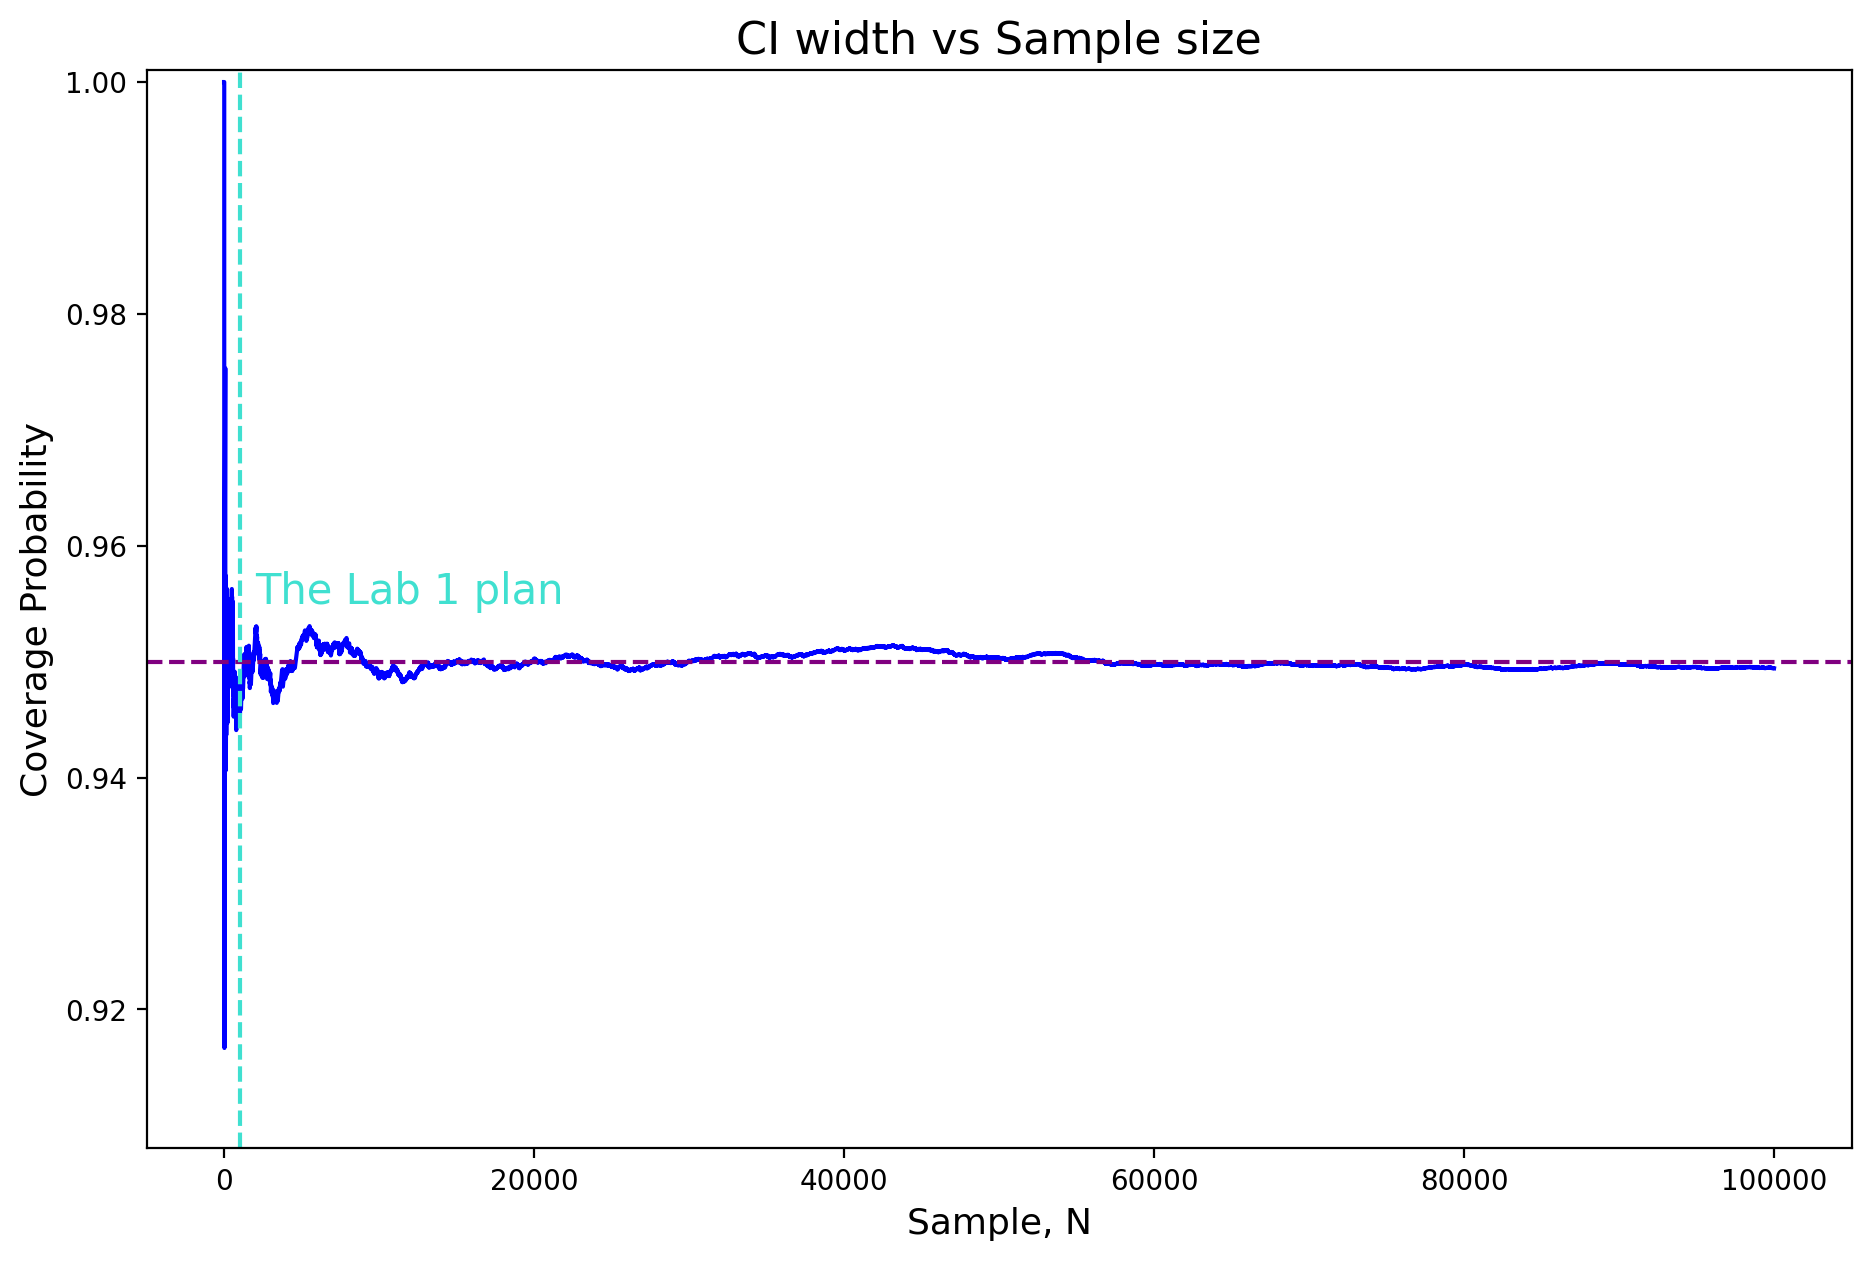

In [15]:
matplotlib_inline.backend_inline.set_matplotlib_formats('retina')
fig, ax = plt.subplots(figsize = (11,7))

ax.plot(coverage_probability, color = "blue")
ax.axhline(0.95, color = "purple", linestyle = "--")
ax.axvline(1000, color = "turquoise", linestyle = "--")
ax.text(2000, 0.955, "The Lab 1 plan", color = "turquoise", size = 15)

ax.set_title("CI width vs Sample size", size = 16)
ax.set_xlabel("Sample, N", size = 13)
ax.set_ylabel("Coverage Probability", size = 13)
ax.set_ylim(0.908, 1.001)

plt.show()


Чому якщо, ефекту нема p-value має рівомірний розподіл?
* p-value це ймовірність отримати таке значення або більш екстримальне. Тому якщо реально різниці нема, то ймоіврність отримати будь-яке значення p-value однакове.

---

Чому біноміальний розподіл має ступінчату форму?
* Бо біноміальний розподіл дискретний, може приймати лише цілі значення

---

**Проводимо A/A тест:**

* Будуєио bar plot частотності для p-value, але рівномірний розподіл в нас не невиходить, бо це правило не працює для дискретних розподелів
* Рахуємо емпірично FPR та будуємо довірчі інтервали то нього
* Будуємо CDF для p-value

---
**Коли A\A тест може давати негативний результат**

* Занадто мала вибірка, тому p-value > alpha
* В 5% які ми закладаємо як FPR
* Різне наповнення груп. Наприклад хотсь з групи B потрапив в групу A
* Різний розмір вибірок, одна менша за іншу

In [17]:
np.random.seed(42)
simulated_experiments_with_H_0 = binom.rvs(p = 0.28, n = N, size = int(1e5))

p_values = []
is_reject = []
for successes in simulated_experiments_with_H_0:
  result = my_binom_test(successes, N, 0.28, conf_int=False, alternative="two-sided")
  p_values.append(result["p_value"])
  is_reject.append(result["reject"])


In [18]:
empirical_FPR = np.mean(is_reject)
ci_empirical_FPR = proportion_confint(np.sum(is_reject), len(is_reject), method="wilson")
print(f"Mean p-value: {np.mean(p_values):.4}")
print(f"Empirical FPR : {empirical_FPR}")
print(f"Confidence Interval : {round(ci_empirical_FPR[0], 4)} -- {round(ci_empirical_FPR[1], 4)}")

Mean p-value: 0.52
Empirical FPR : 0.04601
Confidence Interval : 0.0447 -- 0.0473


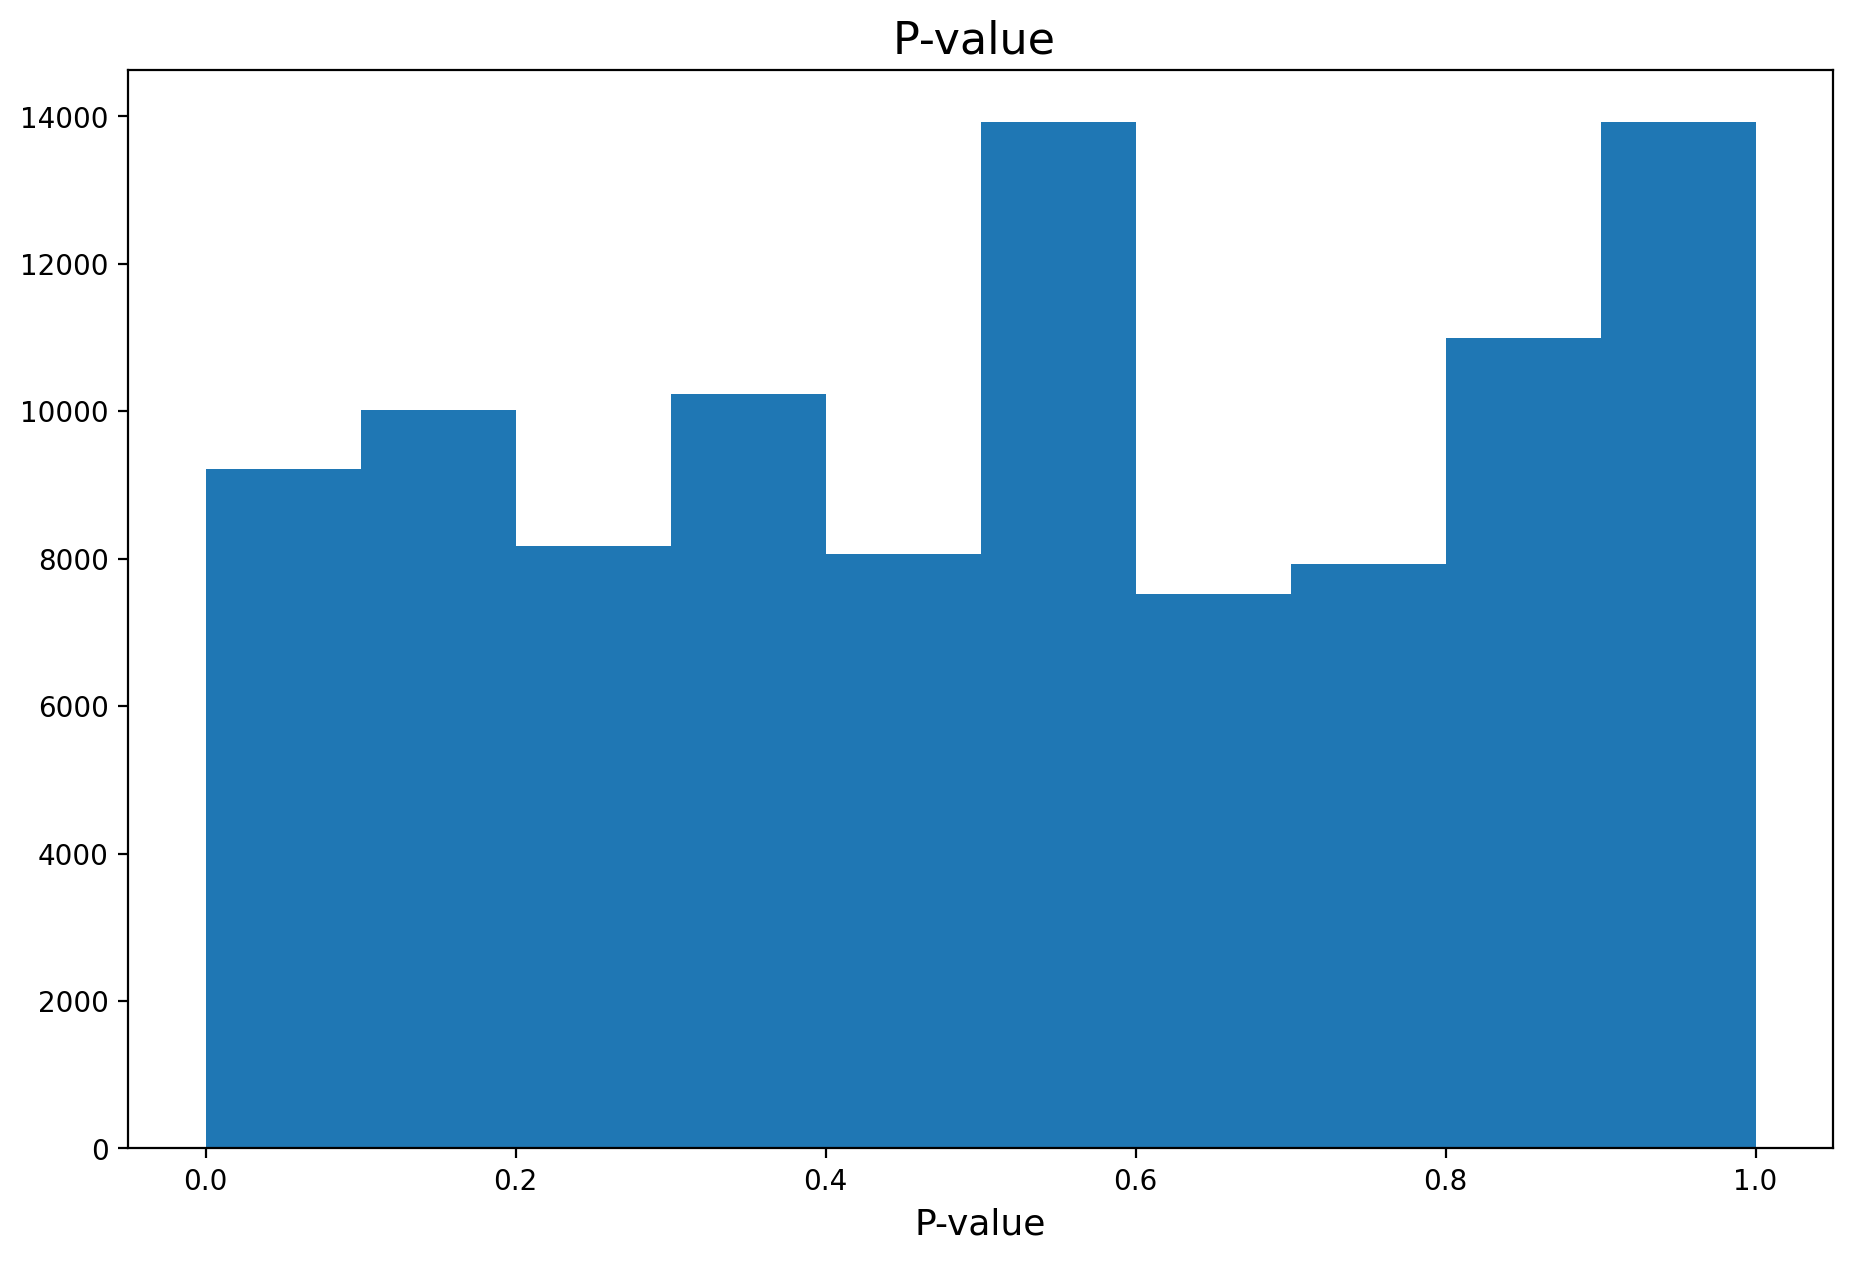

In [19]:
p_values = np.array(p_values)
values, counts = np.unique(p_values, return_counts=True)

fig, ax = plt.subplots(figsize = (11,7))

ax.hist(p_values)
ax.set_title("P-value ", size = 16)
ax.set_xlabel("P-value", size = 13)
ax.set_ylabel("")

plt.show()

**Побудуємо CDF** до p-values

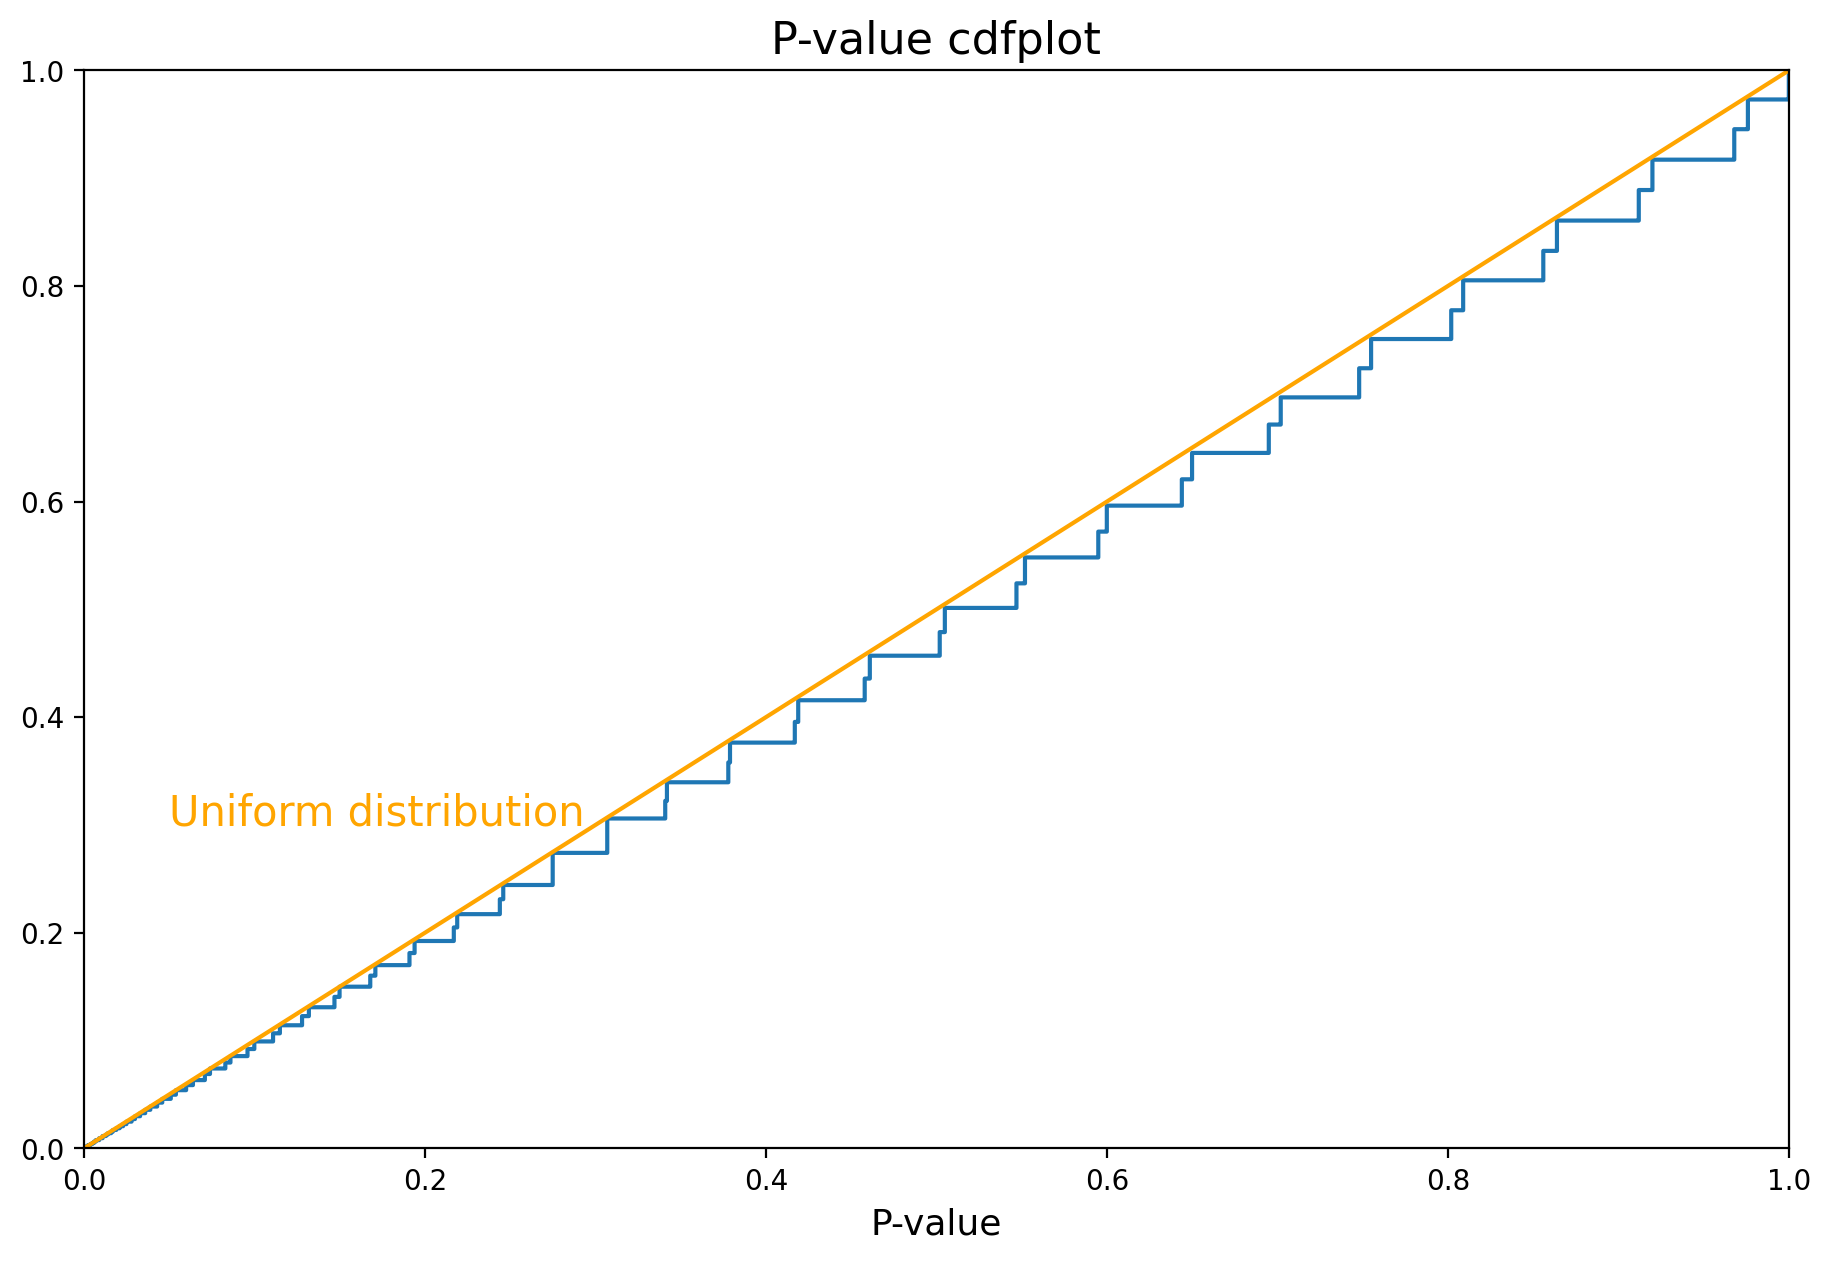

In [20]:
p_values = np.array(p_values)
values, counts = np.unique(p_values, return_counts=True)

fig, ax = plt.subplots(figsize = (11,7))

sns.ecdfplot(p_values, ax = ax)
ax.plot(np.linspace(0, 1, 100), np.linspace(0, 1, 100), color = "orange")
ax.text(0.05, 0.3, "Uniform distribution", color = "orange", size = 15)

ax.set_title("P-value cdfplot", size = 16)
ax.set_xlabel("P-value", size = 13)
ax.set_ylabel("")
ax.set_xlim(0, 1)

plt.show()

## Memo

**Гіпотези були:**
> $H_0$: $μ = 0.28$\
> $H_1$: $μ > 0.28$

* Estimate: 0.305
* Альтернативн $\mu$ = 0.33
* Я обрав правостороній тест, оскільки нас цікавить тільки збільшення
* Confidence Interval : 0.281 -- 1.0
* Ми бачемо що $\mu_0$ < CI lower, тому ми маємо достатньо підстав відхилит $H_0$

---
**Рішення:** впровадити тест


В нас $\mu_0$ < CI low < $\mu^*$. Оскільки $\mu_0$ < CI low ми маємо достатньо підстав, щоб вілхилити $H_0$. CI low < $\mu^*$ це означає, що $\mu^*$ є типовим для нашої вибірки.

---
A/A тест пройшов без зауважень. Питань щодо коректності нема